1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

In [9]:
#reading the file and creating a DataFrame with N equal to the number of rows of the whole dataset
#file_name=":\Users\mpazz\OneDrive\UNIVERSITA'\Laurea magistrale\Primo anno\Laboratory of computational physics\Esercizi-Laboratory-of-computational-physics\Lab_session_6\data_000637.txt"
data = pd.read_csv('./data_000637.txt', delimiter = ',')
data

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25
...,...,...,...,...,...,...
1310715,1,0,62,3869211171,762,14
1310716,1,1,4,3869211171,763,11
1310717,1,0,64,3869211171,764,0
1310718,1,0,139,3869211171,769,0


In [10]:
data.describe()

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
count,1310720.0,1.310720e+06,1.310720e+06,1.310720e+06,1.310720e+06,1.310720e+06
mean,1.0,2.959198e-01,5.582570e+01,3.869206e+09,1.781096e+03,1.332340e+01
std,0.0,4.564553e-01,3.901034e+01,3.183124e+03,1.027795e+03,9.199886e+00
min,1.0,0.000000e+00,1.000000e+00,3.869200e+09,0.000000e+00,0.000000e+00
25%,1.0,0.000000e+00,2.600000e+01,3.869203e+09,8.930000e+02,5.000000e+00
50%,1.0,0.000000e+00,5.700000e+01,3.869207e+09,1.778000e+03,1.300000e+01
75%,1.0,1.000000e+00,6.400000e+01,3.869209e+09,2.670000e+03,2.100000e+01
max,1.0,1.000000e+00,1.390000e+02,3.869211e+09,3.563000e+03,2.900000e+01


The number of BX in a ORBIT corresponds to the maximum value of the BX_COUNTER + 1

In [11]:
n_bx_orbit = max(data['BX_COUNTER']) + 1
print('The number of BX in an ORBIT is ' + str(n_bx_orbit))

The number of BX in an ORBIT is 3564


In [12]:
#finding out the lasting of the whole measurement
tdc_value = (25.0/30.0) * 10**(-9)
len_col = data.shape[0]
starting_time = (data['ORBIT_CNT'][0] * n_bx_orbit + data['BX_COUNTER'][0]) * (25 * 10**(-9)) + data['TDC_MEAS'][0]*tdc_value
ending_time = (data['ORBIT_CNT'][len_col - 1] * n_bx_orbit + data['BX_COUNTER'][len_col - 1]) * (25 * 10**(-9)) + data['TDC_MEAS'][len_col - 1]*tdc_value
lasting = ending_time - starting_time
print('The time lasting of the whole mesurement is ' + str(lasting), 's')

The time lasting of the whole mesurement is 0.9804160933708772 s


In [13]:
#creating a new column containing the absolute time in ns
data['TIME_NS'] = (data['ORBIT_CNT'] * n_bx_orbit + data['BX_COUNTER']) * 25 + data['TDC_MEAS'] * (25.0/30)
data

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,1,0,123,3869200167,2374,26,3.447457e+14
1,1,0,124,3869200167,2374,27,3.447457e+14
2,1,0,63,3869200167,2553,28,3.447457e+14
3,1,0,64,3869200167,2558,19,3.447457e+14
4,1,0,64,3869200167,2760,25,3.447457e+14
...,...,...,...,...,...,...,...
1310715,1,0,62,3869211171,762,14,3.447467e+14
1310716,1,1,4,3869211171,763,11,3.447467e+14
1310717,1,0,64,3869211171,764,0,3.447467e+14
1310718,1,0,139,3869211171,769,0,3.447467e+14


In [15]:
#replacing the elements of the HEAD column with 0 or 1 randomly chosen
data['HEAD']  = np.random.choice([0,1], size = len_col)
data

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,0,0,123,3869200167,2374,26,3.447457e+14
1,1,0,124,3869200167,2374,27,3.447457e+14
2,1,0,63,3869200167,2553,28,3.447457e+14
3,1,0,64,3869200167,2558,19,3.447457e+14
4,0,0,64,3869200167,2760,25,3.447457e+14
...,...,...,...,...,...,...,...
1310715,1,0,62,3869211171,762,14,3.447467e+14
1310716,0,1,4,3869211171,763,11,3.447467e+14
1310717,0,0,64,3869211171,764,0,3.447467e+14
1310718,0,0,139,3869211171,769,0,3.447467e+14


In [18]:
#creating a new DataFrame that contains only the rows corresponding to HEAD=1
new_data = data.copy()
new_data = new_data[new_data['HEAD'] == 1]
new_data

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
1,1,0,124,3869200167,2374,27,3.447457e+14
2,1,0,63,3869200167,2553,28,3.447457e+14
3,1,0,64,3869200167,2558,19,3.447457e+14
5,1,0,63,3869200167,2762,4,3.447457e+14
7,1,0,139,3869200167,2776,0,3.447457e+14
...,...,...,...,...,...,...,...
1310709,1,1,38,3869211171,417,8,3.447467e+14
1310710,1,1,36,3869211171,427,13,3.447467e+14
1310711,1,1,39,3869211171,430,0,3.447467e+14
1310715,1,0,62,3869211171,762,14,3.447467e+14


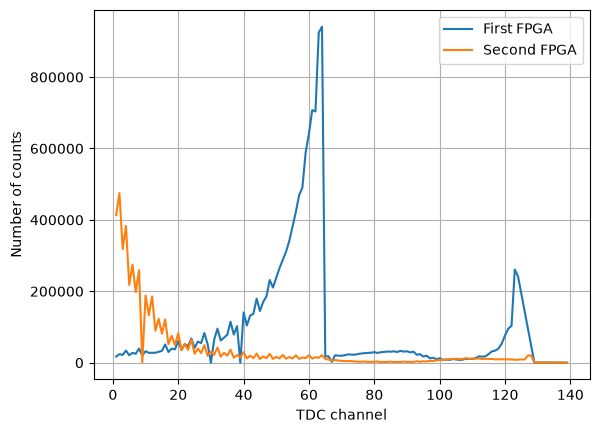

In [38]:
#plotting the number of counts per TDC
df_0 = data[data['FPGA'] == 0].groupby('TDC_CHANNEL', as_index = False)['TDC_MEAS'].sum()
df_1 = data[data['FPGA'] == 1].groupby('TDC_CHANNEL', as_index = False)['TDC_MEAS'].sum()
plt.figure()
plt.plot(df_0['TDC_CHANNEL'], df_0['TDC_MEAS'], label = 'First FPGA')
plt.plot(df_1['TDC_CHANNEL'], df_1['TDC_MEAS'], label = 'Second FPGA')
plt.xlabel('TDC channel')
plt.ylabel('Number of counts')
plt.legend()
plt.grid()
plt.show()


In [37]:
#finding out the three most noisy channels for each FPGA
noisy_1 = df_0['TDC_MEAS'].nlargest(3)
print('The three most noisy channels in the first FPGA are: \n', noisy_1)

noisy_2 = df_1['TDC_MEAS'].nlargest(3)
print('The three most noisy channels in the second FPGA are: \n', noisy_2)

The three most noisy channels in the first FPGA are: 
 58    941085
57    924689
55    707520
Name: TDC_MEAS, dtype: int64
The three most noisy channels in the second FPGA are: 
 1    475221
0    413328
3    383059
Name: TDC_MEAS, dtype: int64


In [67]:
#counting the number of unique orbits and the number if the unique orbits with at least one measurement from TDC_CHANNEL=139
df_orbits = data.groupby('ORBIT_CNT', as_index = False)
n_unique = len(df_orbits)
print('The number of unique orbits is ' + str(n_unique))

mask_139 = (data['TDC_CHANNEL'] == 139 ) & (data['TDC_MEAS'] > 0)
data_filtered = data.loc[mask_139]
df_unique = data_filtered.groupby('ORBIT_CNT')
unique_139 = len(df_unique)
print('The number of unique orbits with at least one measurement from TDC_CHANNEL = 139 is ' + str(unique_139))

The number of unique orbits is 11001
The number of unique orbits with at least one measurement from TDC_CHANNEL = 139 is 0
